# MedSAM Mask Overlay on Worst Predictions

Standalone notebook: for each fold, reload the model's worst predictions and overlay the corresponding MedSAM lesion mask on the same CT crop used in `visualize_nodule_size.ipynb`.

The CT crop comes from the pre-cropped `luna25_nodule_blocks` (as before). The mask, however, lives in the *full-scan* MedSAM instance-label volume (`LUNA25-MedSAM2/instance-labels/<SeriesInstanceUID>.nii.gz`), indexed by an integer instance ID per lesion. To align the two, we crop the mask directly from the full scan around the nodule's real-world coordinate (`CoordX/Y/Z` from the annotations CSV) using the same physical extent (`SIZE_MM`/`SIZE_PX`/`DEPTH_PX`) as the CT patch extraction, reusing `dataloader.extract_patch` for both.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
import torchvision
torchvision.disable_beta_transforms_warning()

import sys
sys.path.insert(0, str(Path.cwd().parent))  # repo root, for experiment_config / dataloader / models
from experiment_config import config
from dataloader import get_data_loader, extract_patch

import matplotlib

# Re-add the missing _get method to RcParams if it doesn't exist
if not hasattr(matplotlib.RcParams, "_get"):
    matplotlib.RcParams._get = lambda self, key: self.get(key)

import matplotlib.pyplot as plt

data_dir = "/datasets/slow/LUNA25"
workspace_root = "/models/hiera-luna25"

annotations_csv_path = Path(f"{data_dir}/LUNA25_Public_Training_Development_Data.csv")
medsam_match_csv_path = Path(f"{data_dir}/medsam_lesion_match_report.csv")
instance_labels_dir = Path(f"{data_dir}/LUNA25-MedSAM2/instance-labels")
predictions_dir = Path(f"{workspace_root}/results/finetune-hiera-3D-20260814")
predictions_csv_path = predictions_dir / "all_folds_predictions.csv"
figures_dir = Path(f"{workspace_root}/figures")
figures_dir.mkdir(exist_ok=True)

num_images = 15
num_worst_predictions_one_fold = 200

## Load annotations and predictions

Same merge/ranking as in `visualize_nodule_size.ipynb` (worst predictions = highest |probability - label|), kept here so this notebook is self-contained.

In [2]:
df_annotations = pd.read_csv(annotations_csv_path)

df_predictions = pd.read_csv(predictions_csv_path)
df_annotations_predictions = pd.merge(df_annotations, df_predictions, on="AnnotationID", how="inner")
df_annotations_predictions.rename(columns={"label_x": "label"}, inplace=True)
df_annotations_predictions["absolute_error"] = abs(
    df_annotations_predictions["probability"] - df_annotations_predictions["label"]
)
df_annotations_predictions.sort_values(by=["absolute_error"], ascending=False, inplace=True)

# maps each AnnotationID to the MedSAM instance ID of its matching lesion in the full-scan mask
df_medsam_match = pd.read_csv(medsam_match_csv_path)[["AnnotationID", "matched", "matched_instance_id"]]
print(f"MedSAM match found for {df_medsam_match['matched'].mean():.1%} of annotations")

MedSAM match found for 98.2% of annotations


## Mask alignment helpers

`itk_image_to_numpy_image` mirrors the header extraction in `inference.py`, so the resulting `origin`/`spacing`/`transform` are in the same numpy (z, y, x) convention that `dataloader.extract_patch` expects. Each nodule's real-world coordinate (`CoordX/Y/Z`) plus its matched MedSAM instance ID are then enough to crop the exact same physical region out of the mask that `luna25_nodule_blocks` already cropped out of the CT scan.

In [3]:
def itk_image_to_numpy_image(input_image):
    """SimpleITK image -> (numpy array, header dict) in the same (z, y, x) convention used by dataloader.extract_patch."""
    def _transform(image, point):
        return np.array(list(reversed(image.TransformContinuousIndexToPhysicalPoint(list(reversed(point))))))

    numpy_image = sitk.GetArrayFromImage(input_image)
    numpy_origin = np.array(list(reversed(input_image.GetOrigin())))
    numpy_spacing = np.array(list(reversed(input_image.GetSpacing())))

    t_origin = _transform(input_image, np.zeros((numpy_image.ndim,)))
    matrix_components = [None] * numpy_image.ndim
    for i in range(numpy_image.ndim):
        v = [0] * numpy_image.ndim
        v[i] = 1
        matrix_components[i] = _transform(input_image, v) - t_origin
    numpy_transform = np.vstack(matrix_components).dot(np.diag(1 / numpy_spacing))

    return numpy_image, {"origin": numpy_origin, "spacing": numpy_spacing, "transform": numpy_transform}


_mask_volume_cache = {}


def get_nodule_mask_patch(annotation_id, output_shape, voxel_spacing):
    """Crops the MedSAM lesion mask for one nodule using the same physical region as its CT patch.

    Returns an all-zero patch (no overlay) when MedSAM found no matching lesion for this annotation.
    """
    ann = df_annotations.loc[df_annotations.AnnotationID == annotation_id].iloc[0]
    match = df_medsam_match.loc[df_medsam_match.AnnotationID == annotation_id]
    fallback_shape = (output_shape[0], 3, output_shape[1], output_shape[2])

    if match.empty or not bool(match.iloc[0]["matched"]):
        return np.zeros(fallback_shape, dtype=np.float32)

    instance_id = match.iloc[0]["matched_instance_id"]
    series_uid = ann["SeriesInstanceUID"]

    if series_uid not in _mask_volume_cache:
        mask_path = instance_labels_dir / f"{series_uid}.nii.gz"
        _mask_volume_cache[series_uid] = (
            itk_image_to_numpy_image(sitk.ReadImage(str(mask_path))) if mask_path.exists() else None
        )

    cached = _mask_volume_cache[series_uid]
    if cached is None:
        return np.zeros(fallback_shape, dtype=np.float32)
    mask_array, mask_header = cached

    # isolate only this lesion's instance so overlapping/neighboring lesions don't bleed into the crop
    binary_mask = (mask_array == instance_id).astype(np.float32)
    world_coord = np.array([ann["CoordZ"], ann["CoordY"], ann["CoordX"]])

    patch = extract_patch(
        CTData=binary_mask,
        coord=world_coord,
        srcVoxelOrigin=mask_header["origin"],
        srcWorldMatrix=mask_header["transform"],
        srcVoxelSpacing=mask_header["spacing"],
        output_shape=output_shape,
        voxel_spacing=voxel_spacing,
        coord_space_world=True,
        mode=config.MODE,
    )
    return patch.astype(np.float32)


def mask_overlay_rgba(mask_slice, color=(1.0, 0.15, 0.15), alpha=0.45, threshold=0.5):
    """Turns a soft (interpolated) mask slice into an RGBA image, transparent outside the lesion."""
    rgba = np.zeros((*mask_slice.shape, 4), dtype=np.float32)
    present = mask_slice >= threshold
    rgba[present, 0] = color[0]
    rgba[present, 1] = color[1]
    rgba[present, 2] = color[2]
    rgba[present, 3] = alpha
    return rgba

## Plot function

Same layout as `plot_images` in `visualize_nodule_size.ipynb` (ground-truth label top-left, annotation ID bottom-left), with the MedSAM lesion mask overlaid in red.

In [4]:
def plot_images_with_mask(images, masks, labels=None, annotation_ids=None, save_plot=True, plot_label=None):
    num_images, height, width = images.shape
    fig, axes = plt.subplots(1, num_images, figsize=(20, 3))
    for i, (ax, image, mask) in enumerate(zip(axes, images, masks)):
        ax.imshow(image, cmap="gray")
        ax.imshow(mask_overlay_rgba(mask))

        bbox = dict(facecolor="white", alpha=0.8, boxstyle="round,pad=0.1")
        if labels is not None:
            ax.text(2, 2, f"{labels[i]}", fontsize=8, color="black", ha="left", va="top", bbox=bbox)
        if annotation_ids is not None:
            ax.text(2, height - 2, f"{annotation_ids[i]}", fontsize=8, color="black", ha="left", va="bottom", bbox=bbox)
        ax.axis("off")
    plt.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01, wspace=0, hspace=0)
    if save_plot:
        plt.savefig(figures_dir / f"{num_images}_worst_predictions_with_mask_{plot_label}.png",
                     dpi=300, bbox_inches="tight", pad_inches=0)
    plt.show()

## Run for every fold

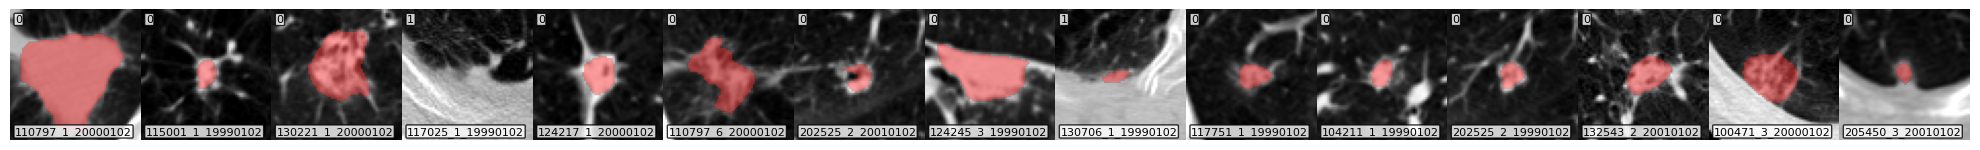

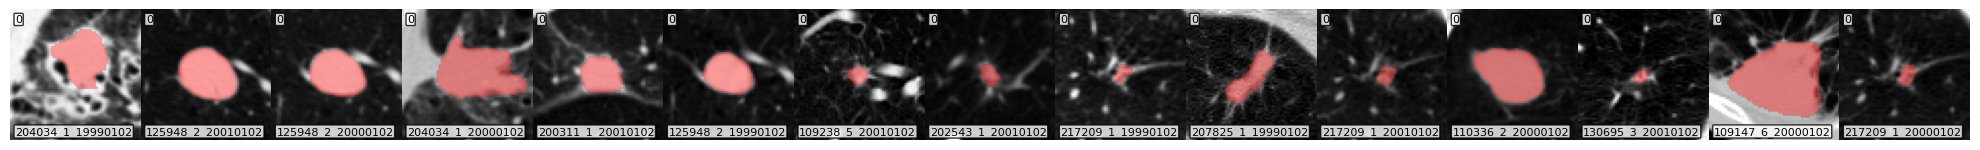

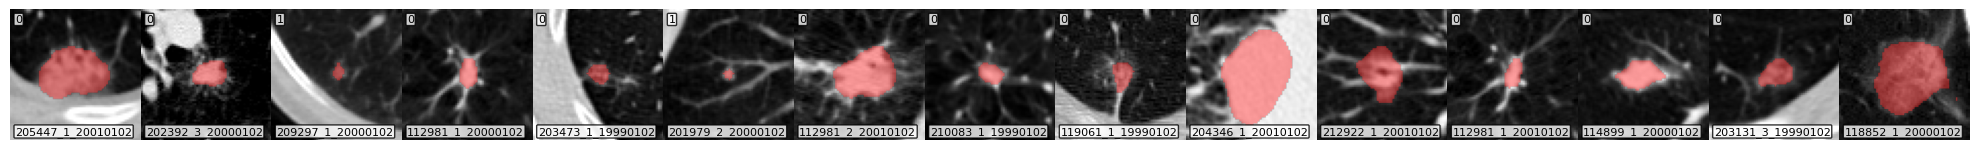

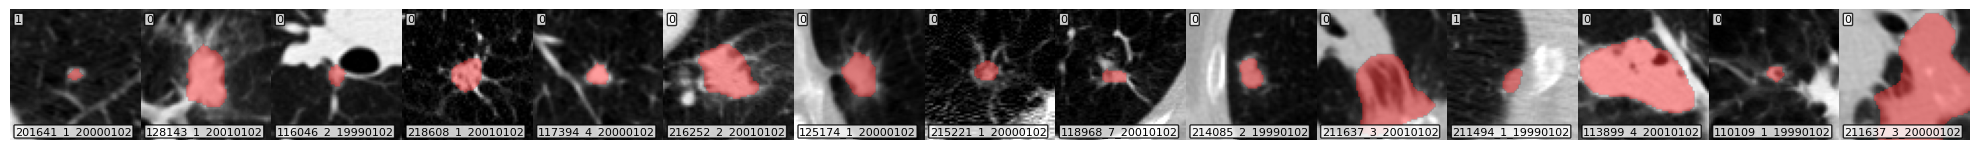

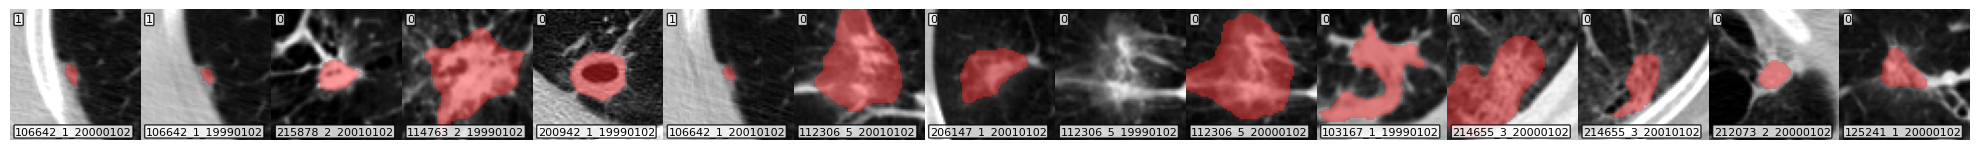

In [5]:
mask_output_shape = (config.DEPTH_PX, config.SIZE_PX, config.SIZE_PX)
mask_voxel_spacing = (config.SIZE_MM / config.SIZE_PX,) * 3

for fold in range(1, 6):
    df_fold = df_annotations_predictions[df_annotations_predictions["fold"] == fold]
    df_worst_preds = df_fold.sort_values("absolute_error", ascending=False).head(num_worst_predictions_one_fold)
    df_images = df_worst_preds.head(num_images)[["AnnotationID", "label"]]

    data_loader = get_data_loader(
        "/datasets/slow/LUNA25/luna25_nodule_blocks",
        df_images,
        mode=config.MODE,
        workers=0,
        batch_size=num_images,
        rotations=None,
        translations=None,
        size_mm=config.SIZE_MM,
        size_px=config.SIZE_PX,
    )
    for data in data_loader:
        images, labels, annotation_ids = data["image"].numpy(), data["label"].squeeze().numpy().tolist(), data["ID"]
        images = images[:, 0, images.shape[2] // 2, :, :]

        masks = np.stack([
            get_nodule_mask_patch(aid, mask_output_shape, mask_voxel_spacing)[mask_output_shape[0] // 2, 0]
            for aid in annotation_ids
        ])

        plot_images_with_mask(images, masks, labels, annotation_ids, plot_label=f"fold_{fold}")